# 05: Does the AI still help on a new kind of image and a new class?

The professor's scope note (28 Nov 2026): *"the integrated model must still help when it sees
new image types and new classes."* Notebooks 02 and 03 measured Kontur on COCO (everyday
photos). This notebook measures the same AI on images **none of Kontur's models was trained
for**, with a class **none of them knows**:

**Kvasir-SEG** [Jha et al. 2020]: 1,000 colonoscopy images with an expert outline of every
**polyp**. Medical images, an unseen class, and objects with soft, low-contrast edges.

| Part | Question | Same protocol as |
|---|---|---|
| **A. MobileSAM** (AI outline) | How good is the outline after 1–5 clicks, and from a box? | notebook 02, part A |
| **B. YOLOE** (suggestions) | Does typing the label "polyp" find polyps, with no training? | notebook 02, part B |
| **C. YOLOE → SAM** | When a suggestion is right, how good is the outline SAM makes from it? | notebook 02, part C |
| **YOLO11n** | Can it suggest "polyp" at all? | |

Everything runs **through the app's own code** (`app/models.py`), as in notebook 02, on the CPU
(about 5–10 minutes). Kvasir-SEG is downloaded once (46 MB) and may be used for research and
education with citation.

**Results:** `eval/results/kvasir/`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "eval" else pathlib.Path.cwd()))
from eval import evallib as E
E.setup()          # work from the project folder
import json, random, zipfile
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm
RES = E.EVAL / "results" / "kvasir"; RES.mkdir(parents=True, exist_ok=True)
print("project folder:", E.ROOT)

project folder: C:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator


c:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator\.venv311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1: get Kvasir-SEG (46 MB, once)

If the download is blocked (on 25 Nov a local network filter blocked `.zip` downloads from
Python), the cell says where to save the file from your browser; then run it again.

In [2]:
KV = E.DATA / "kvasir"
KV_URL = "https://datasets.simula.no/downloads/kvasir-seg.zip"
zpath = E.download(KV_URL, KV / "kvasir-seg.zip", "Kvasir-SEG (46 MB, once)")

def find_dir(name):
    return next((p for p in KV.rglob(name) if p.is_dir() and "__MACOSX" not in p.parts), None)

if find_dir("images") is None:
    with zipfile.ZipFile(zpath) as zf:
        zf.extractall(KV)
IMG_DIR = find_dir("images")
MASK_DIR = IMG_DIR.parent / "masks"
files = sorted(p for p in IMG_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
print(f"{len(files)} images in {IMG_DIR}; masks: {MASK_DIR.exists()}")

1000 images in C:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator\eval\data\kvasir\Kvasir-SEG\images; masks: True


## Step 2: the test objects

100 images, drawn with Kontur's evaluation seed (2026). Each separate region of an expert mask
is one object (an image can show more than one polyp); regions under 16×16 px are skipped, as
in notebook 02. The masks are stored as JPEG, so they are thresholded at half brightness.

In [3]:
N_IMAGES = 100
rng = random.Random(E.SEED)
sample = sorted(rng.sample(files, N_IMAGES))

def mask_for(img_path):
    for cand in (MASK_DIR / img_path.name, *MASK_DIR.glob(img_path.stem + ".*")):
        if cand.exists():
            return cv2.imread(str(cand), cv2.IMREAD_GRAYSCALE) > 127
    raise FileNotFoundError(f"no mask for {img_path.name}")

objects, sizes = [], {}
for f in sample:
    full = mask_for(f)
    sizes[f.name] = full.shape                                   # (h, w)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(full.astype(np.uint8), 8)
    for k in range(1, n):
        x, y, w, h, area = (int(v) for v in stats[k])
        if area < 16 * 16:
            continue
        objects.append({"file": f, "mask": lab == k, "box": [[x, y], [x + w, y + h]], "area": area})
print(f"{len(sample)} images, {len(objects)} polyps; median size "
      f"{np.median([o['area'] for o in objects]) ** 0.5:.0f} px (square side)")

100 images, 109 polyps; median size 176 px (square side)


## A. MobileSAM: outline after 1–5 clicks, and from a box

Exactly notebook 02's protocol (`E.simulate_clicks`): click 1 at the deepest point of the polyp;
each next click at the deepest point of the biggest error (a positive click where SAM missed
polyp, a negative one where it spilled over). Plus one box prompt from the true box.

In [4]:
from app.models import ClickSegmenter
seg = ClickSegmenter()
rows = []
for o in tqdm(objects, desc="SAM polyps", mininterval=5):
    path, gt = o["file"], o["mask"]
    enc = seg.prepare(path)["encode_ms"]
    ious, ms = E.simulate_clicks(seg, path, gt, max_clicks=5)
    rb = seg.segment(path, box=o["box"])
    n85, ok85 = E.noc(ious, 0.85, 5)
    n90, ok90 = E.noc(ious, 0.90, 5)
    rows.append({"image": path.name, "area": o["area"], **{f"iou@{k}": ious[k - 1] for k in range(1, 6)},
                 "iou_box": E.mask_iou(E.polygon_to_mask(rb["polygon"], *gt.shape), gt),
                 "noc85": n85, "reached85": ok85, "noc90": n90, "reached90": ok90,
                 "encode_ms": enc, "decode_ms_mean": float(np.mean(ms)) if ms else None})
sam = pd.DataFrame(rows)
sam.to_csv(RES / "sam_clicks.csv", index=False)
len(sam)

SAM polyps:   0%|          | 0/109 [00:00<?, ?it/s]

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-12700H)


SAM polyps: 100%|██████████| 109/109 [02:06<00:00,  1.16s/it]


109

,COCO (notebook 02),Kvasir-SEG (new domain)
NoC@85 (mean clicks),3.450,3.009
NoC@90 (mean clicks),4.093,3.670
mIoU after 1 click,0.569,0.365
mIoU after 2 clicks,0.654,0.635
mIoU after 3 clicks,0.728,0.718
mIoU after 4 clicks,0.758,0.787
mIoU after 5 clicks,0.775,0.806
mIoU from a box,0.779,0.851
reached 85% within 5 clicks,0.520,0.743
reached 90% within 5 clicks,0.340,0.532


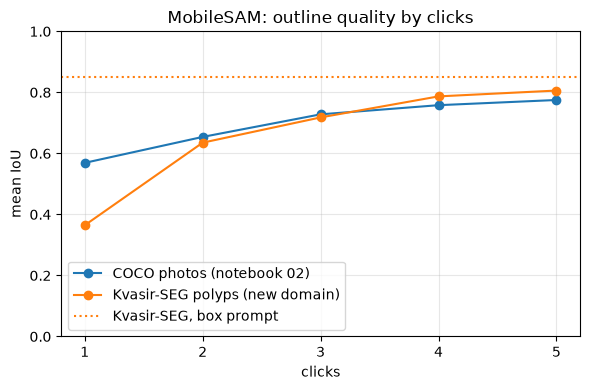

In [5]:
def sam_summary(d):
    return {**{f"mIoU after {k} click{'s' if k > 1 else ''}": d[f"iou@{k}"].mean() for k in range(1, 6)},
            "mIoU from a box": d["iou_box"].mean(),
            "NoC@85 (mean clicks)": d["noc85"].mean(), "reached 85% within 5 clicks": d["reached85"].mean(),
            "NoC@90 (mean clicks)": d["noc90"].mean(), "reached 90% within 5 clicks": d["reached90"].mean()}

coco_q = json.loads((E.EVAL / "results" / "model_quality.json").read_text())
compare_sam = pd.DataFrame({"COCO (notebook 02)": pd.Series(coco_q["sam"]),
                            "Kvasir-SEG (new domain)": pd.Series(sam_summary(sam))}).dropna()
display(compare_sam.round(3))

ks = range(1, 6)
plt.figure(figsize=(6, 4))
plt.plot(ks, [coco_q["sam"][f"mIoU after {k} click{'s' if k > 1 else ''}"] for k in ks], "o-", label="COCO photos (notebook 02)")
plt.plot(ks, [sam[f"iou@{k}"].mean() for k in ks], "o-", label="Kvasir-SEG polyps (new domain)")
plt.axhline(sam["iou_box"].mean(), ls=":", c="C1", label="Kvasir-SEG, box prompt")
plt.xlabel("clicks"); plt.ylabel("mean IoU"); plt.ylim(0, 1); plt.xticks(list(ks))
plt.title("MobileSAM: outline quality by clicks"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RES / "sam_iou_vs_clicks.png", dpi=150); plt.show()

## B. Suggestions: YOLOE with the typed label "polyp" (zero-shot), and YOLO11n

The user types the label **polyp**. YOLO11n only knows the 80 names in its model file, so it
cannot suggest it. YOLOE reads the label as text. It is run exactly as in the app: with the
**decoys** (the other names YOLO11n knows), so an object YOLOE thinks is something else is
dropped instead of being called a polyp. It is also run **without** decoys, to see what the
decoys cost or save on a new domain.

Scoring: COCO box AP (pycocotools) against the expert polyp boxes, and precision / recall at
the app's default 35% confidence (IoU ≥ 0.5).

*Part B measures the detector as the app ran it **before** 28 Nov (`guesses=0`, decoys forced on
or off), so its numbers stay comparable. Part D measures the app as it runs now.*


In [6]:
from app.models import Detector
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

det = Detector()
cov = det.coverage(["polyp"])[0]
print("YOLO11n can suggest 'polyp':", bool(cov["yolo11n"]), "| YOLOE can:", cov["yoloe"])

# ground truth as a small COCO file: one category, the polyp boxes
fid = {f.name: i for i, f in enumerate(sample, 1)}
gt = {"images": [{"id": fid[f.name], "file_name": f.name, "height": sizes[f.name][0], "width": sizes[f.name][1]} for f in sample],
      "categories": [{"id": 1, "name": "polyp"}], "annotations": []}
for k, o in enumerate(objects, 1):
    (x1, y1), (x2, y2) = o["box"]
    gt["annotations"].append({"id": k, "image_id": fid[o["file"].name], "category_id": 1, "iscrowd": 0,
                              "bbox": [x1, y1, x2 - x1, y2 - y1], "area": o["area"]})
C = COCO(); C.dataset = gt; C.createIndex()

def run_yoloe(use_decoys):
    dets, ms, ignored = [], [], {}
    for f in tqdm(sample, desc=f"YOLOE decoys={use_decoys}", mininterval=5):
        r = det.detect("yoloe", f, ["polyp"], conf=0.01, max_det=100, use_decoys=use_decoys, guesses=0)
        ms.append(r["ms"])
        for s in r["suggestions"]:
            (x1, y1), (x2, y2) = s["box"]
            dets.append({"image_id": fid[f.name], "category_id": 1, "bbox": [x1, y1, x2 - x1, y2 - y1], "score": s["score"]})
        for g in r["ignored"]:
            if g["score"] >= 0.35:
                ignored[g["class_name"]] = ignored.get(g["class_name"], 0) + 1
    return dets, ms, ignored

def pr_at(dets, conf=0.35, iou_thr=0.5):
    """Precision / recall at one confidence: greedy one-to-one matching by score."""
    tp = fp = 0
    used = set()
    for d in sorted((d for d in dets if d["score"] >= conf), key=lambda d: -d["score"]):
        x, y, w, h = d["bbox"]; db = [[x, y], [x + w, y + h]]
        best, best_iou = None, iou_thr
        for a in C.imgToAnns[d["image_id"]]:
            ax, ay, aw, ah = a["bbox"]
            v = E.box_iou(db, [[ax, ay], [ax + aw, ay + ah]])
            if a["id"] not in used and v >= best_iou:
                best, best_iou = a["id"], v
        if best is None:
            fp += 1
        else:
            tp += 1; used.add(best)
    n_gt = len(C.anns)
    return {"precision": tp / (tp + fp) if tp + fp else 0.0, "recall": tp / n_gt if n_gt else 0.0,
            "false alarms per image": fp / len(sample)}

def ap(dets):
    if not dets:
        return {"AP": 0.0, "AP50": 0.0, "AP75": 0.0}
    ev = COCOeval(C, C.loadRes(dets), "bbox"); ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"AP": ev.stats[0], "AP50": ev.stats[1], "AP75": ev.stats[2]}

yoloe = {}
for use_decoys in (True, False):
    dets, ms, ignored = run_yoloe(use_decoys)
    tag = "YOLOE, as in the app (with decoys)" if use_decoys else "YOLOE, without decoys"
    yoloe[tag] = {**ap(dets), **{f"{k}@35%": v for k, v in pr_at(dets).items()},
                  "median s per image": float(np.median(ms)) / 1000, "detections": dets,
                  "dropped as another name (top)": dict(sorted(ignored.items(), key=lambda kv: -kv[1])[:5])}
table = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "detections"} for k, v in yoloe.items()})
table["YOLO11n"] = {"AP": "cannot suggest 'polyp'"}
display(table)

YOLO11n can suggest 'polyp': False | YOLOE can: True
creating index...
index created!


YOLOE decoys=True:   0%|          | 0/100 [00:00<?, ?it/s]c:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator\.venv311\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
YOLOE decoys=True: 100%|██████████| 100/100 [00:27<00:00,  3.67it/s]


Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.01s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.029
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.044
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.035
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.063
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.029
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.039
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.039
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.039
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

YOLOE decoys=False: 100%|██████████| 100/100 [00:18<00:00,  5.29it/s]

Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.02s).
Accumulating evaluation results...
DONE (t=0.01s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.232
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.339
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.267
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.133
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.252
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.304
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.337
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.337
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=1

,"YOLOE, as in the app (with decoys)","YOLOE, without decoys",YOLO11n
AP,0.028996,0.231717,cannot suggest 'polyp'
AP50,0.043847,0.33939,NaN
AP75,0.035479,0.267126,NaN
precision@35%,0.0,0.0,NaN
recall@35%,0.0,0.0,NaN
false alarms per image@35%,0.0,0.0,NaN
median s per image,0.20035,0.18325,NaN
dropped as another name (top),"{'person': 20, 'orange': 16, 'cake': 12, 'donu...",{},NaN


## C. YOLOE → SAM: the outline from an accepted suggestion

In the app, accepting a suggestion sends its box to SAM. For each polyp that a suggestion
found (≥ 35% confidence, IoU ≥ 0.5), the outline SAM draws from that suggested box is compared
with the expert mask.

In [7]:
best = max(yoloe, key=lambda k: yoloe[k]["AP"])
dets = sorted((d for d in yoloe[best]["detections"] if d["score"] >= 0.35), key=lambda d: -d["score"])
pipe, used = [], set()
by_img = {}
for k, o in enumerate(objects, 1):
    by_img.setdefault(fid[o["file"].name], []).append((k, o))
for d in dets:
    x, y, w, h = d["bbox"]; db = [[x, y], [x + w, y + h]]
    cand = [(E.box_iou(db, o["box"]), k, o) for k, o in by_img.get(d["image_id"], []) if k not in used]
    if not cand:
        continue
    v, k, o = max(cand, key=lambda t: t[0])
    if v < 0.5:
        continue
    used.add(k)
    r = seg.segment(o["file"], box=db)
    pipe.append({"box_iou": v, "outline_iou": E.mask_iou(E.polygon_to_mask(r["polygon"], *o["mask"].shape), o["mask"])})
pipe = pd.DataFrame(pipe)
print(f"{best}: {len(pipe)} correct suggestions; outline IoU mean {pipe['outline_iou'].mean():.3f}, "
      f"≥ 0.75 for {(pipe['outline_iou'] >= 0.75).mean():.0%}" if len(pipe) else "no correct suggestions at 35%")

no correct suggestions at 35%


## D. What the app shows now: automatic decoys + best guesses

Parts B and C found the problem: YOLOE ranks polyps well but scores them below 5%, so the app's
35% cut showed **nothing**, and the decoys renamed polyps as everyday objects. Since 28 Nov the
app (1) uses decoys only when some label is a familiar name (not here: "polyp" is new), and
(2) shows each custom label's **3 best guesses** per image, marked "guess", whatever their score.

This part runs the detector **exactly as the app now does** (asks at 15%, shows from the 35%
slider default, plus the guesses) and scores what the user would see: is the first box a polyp,
how many polyps are found, and how good SAM's outline is when the user accepts a correct box.

In [8]:
APP_FLOOR, APP_SLIDER = 0.15, 0.35     # the app asks at 15% and shows from the slider's 35%
shown = {}                             # image id -> boxes the user sees, in the order shown
for f in tqdm(sample, desc="YOLOE as the app runs it now", mininterval=5):
    r = det.detect("yoloe", f, ["polyp"], conf=APP_FLOOR)     # app defaults: decoys "auto", 3 guesses
    vis = [s for s in r["suggestions"] if s.get("guess") or s["score"] >= APP_SLIDER]
    shown[fid[f.name]] = vis

def match(boxes, objs):
    """Greedy one-to-one, in the order shown: box -> polyp with IoU >= 0.5."""
    used, hits = set(), []
    for b in boxes:
        best = max(((E.box_iou(b["box"], o["box"]), k) for k, o in objs if k not in used), default=(0, None))
        hits.append(best[1] if best[0] >= 0.5 else None)
        if best[0] >= 0.5:
            used.add(best[1])
    return hits

n_boxes = n_tp = first_ok = with_any = 0
pipe_now = []
for img_id, boxes in shown.items():
    objs = by_img.get(img_id, [])
    hits = match(boxes, objs)
    n_boxes += len(boxes); n_tp += sum(h is not None for h in hits)
    if boxes:
        with_any += 1
        first_ok += hits[0] is not None
    for b, h in zip(boxes, hits):                 # accepting a correct box -> SAM outline
        if h is not None:
            o = dict(objs)[h]
            r = seg.segment(o["file"], box=b["box"])
            pipe_now.append(E.mask_iou(E.polygon_to_mask(r["polygon"], *o["mask"].shape), o["mask"]))

app_now = {
    "images with any box shown": with_any,
    "first box shown is a polyp (of all images)": first_ok / len(sample),
    "first box shown is a polyp (of images with a box)": first_ok / with_any if with_any else 0.0,
    "polyps found among the boxes shown (recall)": n_tp / len(objects),
    "boxes shown that are polyps (precision)": n_tp / n_boxes if n_boxes else 0.0,
    "boxes shown per image": n_boxes / len(sample),
    "accepted correct box -> SAM outline IoU (mean)": float(np.mean(pipe_now)) if pipe_now else None,
    "... outline IoU >= 0.75": float(np.mean(np.array(pipe_now) >= 0.75)) if pipe_now else None,
}
before = {"images with any box shown": 0, "boxes shown per image": 0.0,
          "polyps found among the boxes shown (recall)": 0.0}
display(pd.DataFrame({"app before 28 Nov (35% cut, decoys on)": pd.Series(before),
                      "app now (auto decoys + best guesses)": pd.Series(app_now)}).round(3))
(RES / "app_now.json").write_text(json.dumps(app_now, indent=1))

YOLOE as the app runs it now: 100%|██████████| 100/100 [00:19<00:00,  5.09it/s]


,"app before 28 Nov (35% cut, decoys on)",app now (auto decoys + best guesses)
... outline IoU >= 0.75,NaN,0.850
accepted correct box -> SAM outline IoU (mean),NaN,0.840
boxes shown per image,0.0,2.810
boxes shown that are polyps (precision),NaN,0.285
first box shown is a polyp (of all images),NaN,0.590
first box shown is a polyp (of images with a box),NaN,0.602
images with any box shown,0.0,98.000
polyps found among the boxes shown (recall),0.0,0.734


431

## Save everything, next to the COCO numbers

In [9]:
coco_det = coco_q["detectors"]["yoloe"]
out = {
    "dataset": {"name": "Kvasir-SEG", "images": len(sample), "polyps": len(objects), "seed": E.SEED},
    "sam": sam_summary(sam),
    "sam_coco": coco_q["sam"],
    "yoloe": {k: {kk: vv for kk, vv in v.items() if kk != "detections"} for k, v in yoloe.items()},
    "yoloe_coco_zero_shot": {"AP": coco_det["AP"], "AP50": coco_det["AP50"],
                             "precision@35%": coco_det["precision@35%"], "recall@35%": coco_det["recall@35%"]},
    "yolo11n": "cannot suggest 'polyp' (not among the names in its model file)",
    "pipeline": {"suggester": best, "n": len(pipe),
                 "outline_iou_mean": float(pipe["outline_iou"].mean()) if len(pipe) else None},
}
(RES / "kvasir_quality.json").write_text(json.dumps(out, indent=1, default=float))
for k, v in yoloe.items():
    (RES / f"detections_{'with' if 'with decoys' in k else 'without'}_decoys.json").write_text(json.dumps(v["detections"]))
print(json.dumps({k: v for k, v in out.items() if k in ("dataset", "sam", "pipeline")}, indent=1, default=float))

{
 "dataset": {
  "name": "Kvasir-SEG",
  "images": 100,
  "polyps": 109,
  "seed": 2026
 },
 "sam": {
  "mIoU after 1 click": 0.3645405574866821,
  "mIoU after 2 clicks": 0.6351652863167448,
  "mIoU after 3 clicks": 0.7179033188180273,
  "mIoU after 4 clicks": 0.7868047520454161,
  "mIoU after 5 clicks": 0.8059072058602555,
  "mIoU from a box": 0.8512879899620057,
  "NoC@85 (mean clicks)": 3.0091743119266057,
  "reached 85% within 5 clicks": 0.7431192660550459,
  "NoC@90 (mean clicks)": 3.669724770642202,
  "reached 90% within 5 clicks": 0.5321100917431193
 },
 "pipeline": {
  "suggester": "YOLOE, without decoys",
  "n": 0,
  "outline_iou_mean": null
 }
}


## How to read it

- **SAM on a new domain:** compare the two curves. If the polyp curve rises with clicks to a
  level close to COCO's, the AI outline helps on medical images it never saw, for a class it has
  no name for; that is the class-agnostic design working. Extra clicks needed on soft,
  low-contrast edges are the honest cost.
- **YOLOE with a typed label:** any AP above zero is help YOLO11n cannot give at all. A low AP
  shows where text-only help ends on a specialised domain; the remedy there is to learn from
  the user's own examples (future work: visual prompts, or fine-tuning on Kontur's exports).
- **Decoys on a new domain:** "dropped as another name" lists what YOLOE called the polyps
  instead (if anything). If the decoys drop many true polyps, the app's protection against
  wrong names costs recall on unfamiliar images: a trade-off for the report.

Kvasir-SEG: D. Jha, P. H. Smedsrud, M. A. Riegler, P. Halvorsen, T. de Lange, D. Johansen,
H. D. Johansen. *Kvasir-SEG: A Segmented Polyp Dataset.* MultiMedia Modeling (MMM) 2020.